# Telco Churn - Global Score versus Path-based Structural Importance

This notebook compares four causal recommendation-ranking strategies while keeping the
predictive evaluation environment fixed:

1. `Global Score`
2. `Path-based Structural Importance`, lambda = 0.25
3. `Path-based Structural Importance`, lambda = 0.50
4. `Path-based Structural Importance`, lambda = 0.75

For every strategy, score percentiles are calculated independently after retaining all
rows with a non-empty `Action_Target`. The tie-preserving rules are:

$$
Priority(s)=
\begin{cases}
HIGH, & s\geq P_{75}\\
MEDIUM, & P_{50}\leq s<P_{75}\\
LOW, & s<P_{50}.
\end{cases}
$$

All strategies use the same frozen XGBoost, Random Forest, GBM, and CatBoost models,
the same frozen thresholds, and the same test customers. This notebook performs
predictive intervention simulation only; statistical inference is delegated to the
companion statistical notebook.


## 0. Imports and configuration

In [14]:
import re
import json
import warnings
from pathlib import Path
import os

import numpy as np
import pandas as pd
import joblib
import ipynbname

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, brier_score_loss,
)

warnings.filterwarnings("ignore")

notebook_dir = ipynbname.path().parent
os.chdir(notebook_dir)

TARGET = "Churn"
ID_COL = "CustomerID"
MONTHLY_CHARGES_REDUCTION_PCT = 0.10
APPLY_CANDIDATE_ACTIONS = True

MODEL_DIR = Path("frozen_models")
METADATA_FILE = notebook_dir / MODEL_DIR / "experiment_metadata.json"
TELCO_CANDIDATES = [notebook_dir / Path("Telco-Customer-Churn.xlsx")]
ACTIONS_CANDIDATES = [notebook_dir / Path("Recommended Actions.xlsx")]
OUTPUT_FILE = notebook_dir / Path("Telco_GlobalScore_vs_PathStructural_Intervention_Results.xlsx")

STRATEGY_SHEETS = {
    "Global Score": "Global Score",
    "Path Structural lambda=0.25": "Structural Importance 0.25",
    "Path Structural lambda=0.50": "Structural Importance 0.50",
    "Path Structural lambda=0.75": "Structural Importance 0.75",
}
SCENARIOS = {
    "HIGH": {"HIGH"},
    "HIGH+MEDIUM": {"HIGH", "MEDIUM"},
    "HIGH+MEDIUM+LOW": {"HIGH", "MEDIUM", "LOW"},
}
MODEL_ORDER = ["XGBoost", "RandomForest", "GBM", "CatBoost"]
STRATEGY_ORDER = list(STRATEGY_SHEETS)
SCENARIO_ORDER = list(SCENARIOS)


In [ ]:
print (notebook_dir)
print (MODEL_DIR)

## 1. Load frozen experiment metadata and source files

In [ ]:
def first_existing(paths):
    return next((p for p in paths if p.exists()), None)

if not METADATA_FILE.exists():
    raise FileNotFoundError(f"Missing {METADATA_FILE}")

with open(METADATA_FILE, "r", encoding="utf-8") as stream:
    metadata = json.load(stream)

SEED = int(metadata["seed"])
THRESHOLD_METHOD = metadata.get("threshold_method", "f1")
thresholds = {k: float(v) for k, v in metadata["thresholds"].items()}
expected_models = metadata.get("models", MODEL_ORDER)
catboost_cat_cols = metadata.get("catboost_native_categoricals", [])
catboost_num_cols = metadata.get("catboost_numeric_columns", [])
catboost_numeric_medians = pd.Series(metadata.get("catboost_numeric_medians", {}), dtype=float)

TELCO_FILE = first_existing(TELCO_CANDIDATES)
ACTIONS_FILE = first_existing(ACTIONS_CANDIDATES)
if TELCO_FILE is None:
    raise FileNotFoundError("Missing Telco-Customer-Churn.xlsx")
if ACTIONS_FILE is None:
    raise FileNotFoundError("Missing Recommended Actions.xlsx")

xls = pd.ExcelFile(TELCO_FILE)
telco = pd.read_excel(TELCO_FILE, sheet_name="Dataset" if "Dataset" in xls.sheet_names else 0)
if "TotalCharges" in telco.columns:
    telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")

print("Frozen seed:", SEED)
print("Frozen thresholds:", thresholds)
print("Actions workbook:", ACTIONS_FILE)
print("Telco shape:", telco.shape)


## 2. Load and prioritize the four recommendation strategies

The score column is called `Global Score` in every source sheet, including the three
path-based sheets. In the latter, it represents the aggregated path-based structural
importance score for the lambda value named by the sheet.

Percentiles are computed **within each strategy**. Equal-to-threshold scores remain in
the higher priority group, preserving ties.


In [17]:
REQUIRED_ACTION_COLUMNS = {
    "Source", "Sign", "Action_Target", "Recommended_Action", "Global Rank", "Global Score"
}

actions_by_strategy = {}
priority_threshold_rows = []

for strategy, sheet in STRATEGY_SHEETS.items():
    actions = pd.read_excel(ACTIONS_FILE, sheet_name=sheet)
    missing = REQUIRED_ACTION_COLUMNS.difference(actions.columns)
    if missing:
        raise ValueError(f"{sheet}: missing columns {sorted(missing)}")

    target_text = actions["Action_Target"].fillna("").astype(str).str.strip()
    actions = actions[target_text.ne("") & target_text.str.lower().ne("nan")].copy()
    actions["Global Score"] = pd.to_numeric(actions["Global Score"], errors="raise")
    p50 = float(actions["Global Score"].quantile(0.50))
    p75 = float(actions["Global Score"].quantile(0.75))

    def classify_priority(score):
        if score >= p75:
            return "HIGH"
        if score >= p50:
            return "MEDIUM"
        return "LOW"

    actions["Priority"] = actions["Global Score"].apply(classify_priority)
    actions["Strategy"] = strategy
    actions["Source_Sheet"] = sheet
    actions_by_strategy[strategy] = actions
    priority_threshold_rows.append({
        "Strategy": strategy, "Source_Sheet": sheet, "Eligible_Action_Rows": len(actions),
        "P50": p50, "P75": p75,
        "HIGH_Rows": int((actions["Priority"] == "HIGH").sum()),
        "MEDIUM_Rows": int((actions["Priority"] == "MEDIUM").sum()),
        "LOW_Rows": int((actions["Priority"] == "LOW").sum()),
    })

priority_thresholds_df = pd.DataFrame(priority_threshold_rows)
all_prioritized_actions_df = pd.concat(actions_by_strategy.values(), ignore_index=True)

bad_targets = sorted(set(all_prioritized_actions_df["Action_Target"].astype(str)) - set(telco.columns))
if bad_targets:
    raise ValueError("Action_Target not found in Telco data: " + ", ".join(bad_targets))

display(priority_thresholds_df)
display(all_prioritized_actions_df.sort_values(["Strategy", "Global Score", "Global Rank"], ascending=[True, False, True]))


,Strategy,Source_Sheet,Eligible_Action_Rows,P50,P75,HIGH_Rows,MEDIUM_Rows,LOW_Rows
0,Global Score,Global Score,15,0.142857,0.285714,4,4,7
1,Path Structural lambda=0.25,Structural Importance 0.25,15,0.111111,0.250000,4,4,7
2,Path Structural lambda=0.50,Structural Importance 0.50,15,0.111111,0.257937,4,4,7
3,Path Structural lambda=0.75,Structural Importance 0.75,15,0.111111,0.230159,4,4,7


,Source,Sign,Actionable,Action_Target,Recommended_Action,Rationale,Global Rank,Global Score,Priority,Strategy,Source_Sheet
0,Contract_Month-to-month,+,YES,Contract,Contract = One year,"Month-to-month increases churn, while One-year...",1,0.468254,HIGH,Global Score,Global Score
1,InternetService_Fiber_optic,+,YES,InternetService,InternetService = DSL (candidate),Fiber optic has a positive churn edge. No inte...,2,0.452381,HIGH,Global Score,Global Score
2,MonthlyCharges,+,YES,MonthlyCharges,Reduce MonthlyCharges,Higher MonthlyCharges has a positive edge to C...,3,0.428571,HIGH,Global Score,Global Score
3,OnlineBackup_Yes,-,YES,OnlineBackup,OnlineBackup = Yes,"Yes has a negative edge to Churn, so recommend...",4,0.333333,HIGH,Global Score,Global Score
4,PhoneService,-,YES,PhoneService,PhoneService = Yes,PhoneService has a negative edge to Churn; rec...,5,0.238095,MEDIUM,Global Score,Global Score
5,MultipleLines_No_phone_service,+,NO,PhoneService,PhoneService = Yes,No phone service is a churn-increasing state; ...,5,0.238095,MEDIUM,Global Score,Global Score
6,InternetService_No,+,YES,InternetService,InternetService = DSL (candidate),Move away from No internet service. Fiber opti...,6,0.142857,MEDIUM,Global Score,Global Score
7,PaymentMethod_Mailed_check,-,YES,PaymentMethod,PaymentMethod = Mailed check,Mailed check has the strongest negative Paymen...,6,0.142857,MEDIUM,Global Score,Global Score
8,MultipleLines_Yes,-,YES,MultipleLines,MultipleLines = Yes,"Yes has a negative edge to Churn, so recommend...",7,0.111111,LOW,Global Score,Global Score
9,Contract_One_year,-,YES,Contract,Contract = One year,The One-year contract has a negative edge to C...,8,0.095238,LOW,Global Score,Global Score


## 3. Recreate the frozen 70/15/15 split and load the four models

In [18]:
train_df, temp_df = train_test_split(
    telco, test_size=0.30, stratify=telco[TARGET], random_state=SEED
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=SEED
)

X_test = test_df.drop(columns=[TARGET, ID_COL]).copy()
y_test = test_df[TARGET].astype(str).str.lower().eq("yes").astype(int)

model_files = metadata.get("model_files", {name: f"{name}.joblib" for name in expected_models})
models = {}
for model_name in expected_models:
    path = MODEL_DIR / model_files.get(model_name, f"{model_name}.joblib")
    if not path.exists():
        raise FileNotFoundError(f"Missing frozen model: {path}")
    models[model_name] = joblib.load(path)

assert set(models) == set(thresholds), "Model and threshold names do not match"
print("Loaded:", list(models))


Loaded: ['XGBoost', 'RandomForest', 'GBM', 'CatBoost']


## 4. Frozen prediction functions and baseline performance

In [19]:
def transform_catboost_frozen(X):
    X_cb = X.copy()
    for col in catboost_num_cols:
        if col in X_cb.columns:
            median = float(catboost_numeric_medians[col]) if col in catboost_numeric_medians.index else pd.to_numeric(X_cb[col], errors="coerce").median()
            X_cb[col] = pd.to_numeric(X_cb[col], errors="coerce").fillna(median).astype(float)
    for col in catboost_cat_cols:
        if col in X_cb.columns:
            X_cb[col] = X_cb[col].fillna("__MISSING__").astype(str)
    return X_cb


def predict_proba_frozen(model_name, X_raw):
    X_model = transform_catboost_frozen(X_raw) if model_name == "CatBoost" else X_raw
    return models[model_name].predict_proba(X_model)[:, 1]


def classification_metrics(y_true, probs, threshold):
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "AUC": roc_auc_score(y_true, probs), "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0), "Threshold": threshold,
        "True_Positives": int(tp), "False_Positives": int(fp),
        "False_Negatives": int(fn), "True_Negatives": int(tn),
        "Predicted_Positive_TP_plus_FP": int(tp + fp),
    }

baseline_probs, baseline_pred, baseline_rows = {}, {}, []
for model_name in expected_models:
    probs = predict_proba_frozen(model_name, X_test)
    pred = probs >= thresholds[model_name]
    baseline_probs[model_name] = probs
    baseline_pred[model_name] = pred
    baseline_rows.append({"Model": model_name, **classification_metrics(y_test, probs, thresholds[model_name])})

baseline_performance_df = pd.DataFrame(baseline_rows)
display(baseline_performance_df)


,Model,AUC,Accuracy,Precision,Recall,F1,Threshold,True_Positives,False_Positives,False_Negatives,True_Negatives,Predicted_Positive_TP_plus_FP
0,XGBoost,0.862109,0.793756,0.602606,0.658363,0.629252,0.380,185,122,96,654,307
1,RandomForest,0.857942,0.792810,0.600649,0.658363,0.628183,0.380,185,123,96,653,308
2,GBM,0.860818,0.794702,0.600629,0.679715,0.637730,0.365,191,127,90,649,318
3,CatBoost,0.861591,0.794702,0.606667,0.647687,0.626506,0.380,182,118,99,658,300


## 4A. Baseline probability calibration and classification-threshold sensitivity

These diagnostics use the **untouched independent test subset** and the original frozen models. The Brier score measures the mean squared difference between baseline predicted churn probability and observed churn (lower is better). The reliability diagram is descriptive and uses equally spaced probability bins; sparse bins may be unstable.

The conventional threshold of **0.50** is compared with each model's **validation-optimized threshold** for *baseline classification only*. The intervention experiment below continues to use the optimized thresholds. Neither model parameters nor probabilities are recalibrated. ROC AUC and Brier score do not change with the classification threshold.


,Model,Test_N,Observed_Churn_Rate,Test_ROC_AUC,Brier_Score
0,XGBoost,1057,0.265847,0.862109,0.130230
1,RandomForest,1057,0.265847,0.857942,0.132712
2,GBM,1057,0.265847,0.860818,0.130606
3,CatBoost,1057,0.265847,0.861591,0.130175


,Model,Threshold_Type,Threshold,Precision,Recall,F1,Accuracy,True_Positives,False_Positives,False_Negatives,True_Negatives,Customers_Targeted_TP_plus_FP,Pct_Test_Customers_Targeted
0,XGBoost,Optimized,0.380,0.602606,0.658363,0.629252,0.793756,185,122,96,654,307,29.044465
1,XGBoost,Conventional_0.50,0.500,0.702439,0.512456,0.592593,0.812677,144,61,137,715,205,19.394513
2,RandomForest,Optimized,0.380,0.600649,0.658363,0.628183,0.792810,185,123,96,653,308,29.139073
3,RandomForest,Conventional_0.50,0.500,0.686275,0.498221,0.577320,0.806055,140,64,141,712,204,19.299905
4,GBM,Optimized,0.365,0.600629,0.679715,0.637730,0.794702,191,127,90,649,318,30.085147
5,GBM,Conventional_0.50,0.500,0.680365,0.530249,0.596000,0.808893,149,70,132,706,219,20.719016
6,CatBoost,Optimized,0.380,0.606667,0.647687,0.626506,0.794702,182,118,99,658,300,28.382214
7,CatBoost,Conventional_0.50,0.500,0.699507,0.505338,0.586777,0.810785,142,61,139,715,203,19.205298


XGBoost threshold comparison (optimized minus conventional):


,Metric,Threshold 0.38,Threshold 0.50,Difference
0,True Positives (TP),185,144,+41
1,False Negatives (FN),96,137,-41
2,Recall,65.84%,51.25%,+14.59 pp
3,False Positives (FP),122,61,+61
4,Precision,60.26%,70.24%,-9.98 pp
5,Customers targeted (TP+FP),307,205,+102
6,% of test customers targeted,29.04%,19.39%,+9.65 pp


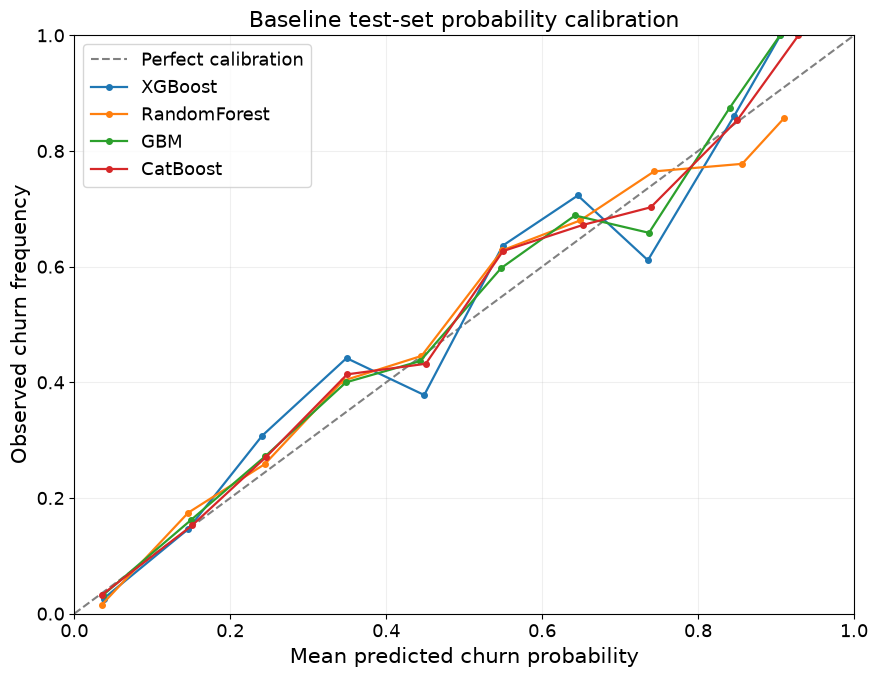

Calibration figure: D:\ProjectsAI\Systems-MDPI\Inputs\final_results\Telco_Baseline_Calibration.png


In [20]:
# Reuse the baseline probabilities already computed above; no retraining or resampling.
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

calibration_rows = []
threshold_comparison_rows = []
calibration_bin_rows = []
y_test_array = y_test.to_numpy(dtype=int)

for model_name in expected_models:
    probs = np.asarray(baseline_probs[model_name], dtype=float)
    brier = brier_score_loss(y_test_array, probs)
    calibration_rows.append({
        "Model": model_name,
        "Test_N": len(y_test_array),
        "Observed_Churn_Rate": float(y_test_array.mean()),
        "Test_ROC_AUC": roc_auc_score(y_test_array, probs),
        "Brier_Score": brier,
    })
    for label, threshold in (("Optimized", thresholds[model_name]), ("Conventional_0.50", 0.5)):
        row = classification_metrics(y_test_array, probs, threshold)
        threshold_comparison_rows.append({
            "Model": model_name,
            "Threshold_Type": label,
            **row,
            "Customers_Targeted_TP_plus_FP": row["True_Positives"] + row["False_Positives"],
            "Pct_Test_Customers_Targeted": 100.0 * (row["True_Positives"] + row["False_Positives"]) / len(y_test_array),
            "FPR": row["False_Positives"] / (row["False_Positives"] + row["True_Negatives"]),
            "Specificity": row["True_Negatives"] / (row["False_Positives"] + row["True_Negatives"]),
            "Brier_Score": brier,
        })

    # Equal-width bins, with bin counts for transparent interpretation.
    edges = np.linspace(0.0, 1.0, 11)
    bin_index = np.clip(np.digitize(probs, edges[1:-1], right=False), 0, 9)
    for j in range(10):
        mask = bin_index == j
        calibration_bin_rows.append({
            "Model": model_name,
            "Bin": j + 1,
            "Bin_Lower": edges[j],
            "Bin_Upper": edges[j + 1],
            "N": int(mask.sum()),
            "Mean_Predicted_Probability": float(probs[mask].mean()) if mask.any() else np.nan,
            "Observed_Churn_Frequency": float(y_test_array[mask].mean()) if mask.any() else np.nan,
        })

calibration_df = pd.DataFrame(calibration_rows)
threshold_comparison_df = pd.DataFrame(threshold_comparison_rows)
calibration_bins_df = pd.DataFrame(calibration_bin_rows)

display(calibration_df)
display(threshold_comparison_df[[
    "Model", "Threshold_Type", "Threshold", "Precision", "Recall", "F1",
    "Accuracy", "True_Positives", "False_Positives", "False_Negatives", "True_Negatives",
    "Customers_Targeted_TP_plus_FP", "Pct_Test_Customers_Targeted",
]])

# XGBoost threshold comparison, matching the supplied table and adding targeting coverage.
# Values are derived from the frozen model predictions, not entered manually.
xgb_threshold_rows = threshold_comparison_df.loc[
    threshold_comparison_df["Model"].eq("XGBoost")
].set_index("Threshold_Type")
xgb_opt = xgb_threshold_rows.loc["Optimized"]
xgb_conv = xgb_threshold_rows.loc["Conventional_0.50"]

xgb_metrics = [
    ("True Positives (TP)", "True_Positives", "count"),
    ("False Negatives (FN)", "False_Negatives", "count"),
    ("Recall", "Recall", "rate"),
    ("False Positives (FP)", "False_Positives", "count"),
    ("Precision", "Precision", "rate"),
    ("Customers targeted (TP+FP)", "Customers_Targeted_TP_plus_FP", "count"),
    ("% of test customers targeted", "Pct_Test_Customers_Targeted", "percentage"),
]

def _format_comparison(value, kind):
    if kind == "rate":
        return f"{100 * value:.2f}%"
    if kind == "percentage":
        return f"{value:.2f}%"
    return f"{int(value)}"

xgb_comparison_rows = []
for metric, column, kind in xgb_metrics:
    a, b = float(xgb_opt[column]), float(xgb_conv[column])
    difference = (100 * (a - b)) if kind == "rate" else (a - b)
    difference_str = (f"{difference:+.2f} pp" if kind in ("rate", "percentage")
                      else f"{difference:+.0f}")
    xgb_comparison_rows.append({
        "Metric": metric,
        f"Threshold {xgb_opt['Threshold']:.2f}": _format_comparison(a, kind),
        f"Threshold {xgb_conv['Threshold']:.2f}": _format_comparison(b, kind),
        "Difference": difference_str,
    })
xgb_threshold_summary_df = pd.DataFrame(xgb_comparison_rows)
print("XGBoost threshold comparison (optimized minus conventional):")
display(xgb_threshold_summary_df)

# One calibration plot; no fitted calibration transform is applied.
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "figure.titlesize": 18,
})
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.5, label="Perfect calibration")
for model_name in expected_models:
    bins = calibration_bins_df[(calibration_bins_df["Model"] == model_name) & (calibration_bins_df["N"] > 0)]
    ax.plot(bins["Mean_Predicted_Probability"], bins["Observed_Churn_Frequency"],
            marker="o", linewidth=1.6, markersize=4, label=model_name)
ax.set(xlabel="Mean predicted churn probability", ylabel="Observed churn frequency",
       title="Baseline test-set probability calibration", xlim=(0, 1), ylim=(0, 1))
ax.grid(alpha=0.2)
ax.legend(fontsize=13)
fig.tight_layout()
CALIBRATION_FIGURE = notebook_dir / "Telco_Baseline_Calibration.png"
fig.savefig(CALIBRATION_FIGURE, dpi=600, bbox_inches="tight")
plt.show()
print("Calibration figure:", CALIBRATION_FIGURE)


## 5. Parse recommendation actions consistently across strategies

In [21]:
CATEGORY_VALUES = {
    "PhoneService": ["No", "Yes"],
    "MultipleLines": ["No", "Yes", "No phone service"],
    "InternetService": ["DSL", "Fiber optic", "No"],
    "OnlineSecurity": ["No", "Yes", "No internet service"],
    "OnlineBackup": ["No", "Yes", "No internet service"],
    "DeviceProtection": ["No", "Yes", "No internet service"],
    "TechSupport": ["No", "Yes", "No internet service"],
    "StreamingTV": ["No", "Yes", "No internet service"],
    "StreamingMovies": ["No", "Yes", "No internet service"],
    "Contract": ["Month-to-month", "One year", "Two year"],
    "PaymentMethod": ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
}

def norm(value):
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())

def decode_source_state(source, target):
    if target not in CATEGORY_VALUES:
        return None
    if norm(source) == norm(target) and "Yes" in CATEGORY_VALUES[target]:
        return "Yes"
    for value in CATEGORY_VALUES[target]:
        if norm(value) in norm(source):
            return value
    return None

def normalize_recommended_value(target, value):
    mapping = {
        ("PaymentMethod", "Credit card"): "Credit card (automatic)",
        ("PaymentMethod", "Bank transfer"): "Bank transfer (automatic)",
    }
    return mapping.get((target, value), value)

def parse_action(row):
    text = str(row["Recommended_Action"]).strip()
    target = str(row["Action_Target"]).strip()
    candidate = "(candidate)" in text.lower()
    if target == "MonthlyCharges" and text.lower().startswith("reduce"):
        return {"kind": "reduce", "target": target, "value": MONTHLY_CHARGES_REDUCTION_PCT, "candidate": candidate}
    match = re.search(r"=\s*(.+)$", text)
    if not match:
        raise ValueError(f"Cannot parse action for {row['Source']}: {text}")
    value = re.sub(r"\s*\(candidate\)\s*$", "", match.group(1).strip(), flags=re.I)
    return {"kind": "set", "target": target, "value": normalize_recommended_value(target, value), "candidate": candidate}

for strategy, actions in actions_by_strategy.items():
    actions = actions.copy()
    actions["_parsed"] = actions.apply(parse_action, axis=1)
    actions["_source_state"] = actions.apply(lambda r: decode_source_state(r["Source"], r["Action_Target"]), axis=1)
    actions["Is_Candidate_Action"] = actions["_parsed"].apply(lambda x: bool(x["candidate"]))
    actions_by_strategy[strategy] = actions


## 6. Intervention engine

Actions are applied only to baseline predicted-positive customers. Positive-sign categorical actions are restricted to the corresponding source state, while negative-sign actions may target any eligible customer. Primary service activations also trigger deterministic consistency adjustments: `InternetService: No → DSL` sets six internet-dependent attributes to `No`, while `Fiber optic → DSL` preserves them; `PhoneService: No → Yes` sets `MultipleLines` to `No`. Subsequent prioritized actions can still change these dependent attributes when eligible.


In [22]:
INTERNET_DEPENDENT = {
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
}

def enforce_service_activation_dependencies(modified, target, value, changed_mask, previous_values):
    """Apply deterministic consistency adjustments after a primary service activation.

    InternetService: No -> DSL sets all six add-ons to No; Fiber optic -> DSL
    preserves their existing Yes/No values. PhoneService: No -> Yes sets
    MultipleLines to No. No other service transitions are handled here.
    """
    if target == "InternetService" and value == "DSL":
        activated = changed_mask & (previous_values == "No")
        for dependent in INTERNET_DEPENDENT:
            if dependent not in modified.columns:
                raise ValueError(f"Missing internet-dependent column: {dependent}")
            modified.loc[activated, dependent] = "No"
    elif target == "PhoneService" and value == "Yes":
        activated = changed_mask & (previous_values == "No")
        if "MultipleLines" not in modified.columns:
            raise ValueError("Missing phone-dependent column: MultipleLines")
        modified.loc[activated, "MultipleLines"] = "No"


def apply_scenario(df_original, baseline_positive_mask, actions, allowed_priorities):
    modified = df_original.copy(deep=True)
    log_rows = []
    selected = actions[actions["Priority"].isin(allowed_priorities)].sort_values(
        ["Global Score", "Global Rank"], ascending=[False, True]
    )
    already_changed = {
        target: np.zeros(len(modified), dtype=bool)
        for target in selected["Action_Target"].dropna().astype(str).unique() if target.strip()
    }

    for _, row in selected.iterrows():
        rec = row["_parsed"]
        if rec["candidate"] and not APPLY_CANDIDATE_ACTIONS:
            continue
        target = rec["target"]
        if target not in modified.columns:
            raise ValueError(f"Unknown target column: {target}")
        mask = np.asarray(baseline_positive_mask, dtype=bool).copy()
        if row["Sign"] == "+" and row["_source_state"] is not None:
            mask &= modified[target].astype(str).to_numpy() == str(row["_source_state"])
        mask &= ~already_changed[target]

        if rec["kind"] == "set":
            mask &= modified[target].astype(str).to_numpy() != str(rec["value"])
            if target in INTERNET_DEPENDENT and rec["value"] == "Yes":
                mask &= modified["InternetService"].astype(str).to_numpy() != "No"
            if target == "MultipleLines" and rec["value"] == "Yes":
                mask &= modified["PhoneService"].astype(str).to_numpy() == "Yes"
            previous_values = modified[target].astype(str).to_numpy().copy()
            modified.loc[mask, target] = rec["value"]
            enforce_service_activation_dependencies(
                modified, target, rec["value"], mask, previous_values
            )
        elif rec["kind"] == "reduce":
            modified.loc[mask, target] = modified.loc[mask, target].astype(float) * (1.0 - rec["value"])
        else:
            raise ValueError(f"Unknown action kind: {rec['kind']}")

        already_changed[target] |= mask
        log_rows.append({
            "Source": row["Source"], "Sign": row["Sign"], "Action_Target": target,
            "Recommended_Action": row["Recommended_Action"], "Priority": row["Priority"],
            "Score": row["Global Score"], "Rank": row["Global Rank"],
            "Is_Candidate_Action": bool(rec["candidate"]), "Changed_Customers": int(mask.sum()),
        })
    return modified, pd.DataFrame(log_rows)


## 7. Evaluate TP, FP, and TP+FP (complete high-risk cohort)

For model $m$, customer $i$, strategy $r$, and scenario $s$:

$$
\Delta P_{i,m,r,s}=P_{before}-P_{after}.
$$

Three cohorts are retained:

- **TP:** observed churners correctly classified as high risk;
- **FP:** observed non-churners classified as high risk;
- **TP+FP:** all baseline predicted-positive customers, corresponding to CARRE's
  complete high-risk evaluation cohort.

`Threshold_Crossed` means baseline predicted Yes becomes predicted No.
`Effective` means $\Delta P>0$, irrespective of threshold crossing.


In [23]:
scenario_rows, cohort_rows, customer_rows, application_logs = [], [], [], []
actual_churn = y_test.to_numpy().astype(bool)

for strategy in STRATEGY_ORDER:
    actions = actions_by_strategy[strategy]
    for model_name in expected_models:
        before_probs = baseline_probs[model_name]
        before_pred = baseline_pred[model_name]
        threshold = thresholds[model_name]
        masks = {
            "TP": before_pred & actual_churn,
            "FP": before_pred & (~actual_churn),
            "TP+FP": before_pred,
        }

        for scenario_name, priority_set in SCENARIOS.items():
            modified_test_df, app_log = apply_scenario(test_df, before_pred, actions, priority_set)
            X_modified = modified_test_df.drop(columns=[TARGET, ID_COL])
            after_probs = predict_proba_frozen(model_name, X_modified)
            after_pred = after_probs >= threshold
            delta = before_probs - after_probs

            scenario_record = {
                "Strategy": strategy, "Model": model_name, "Scenario": scenario_name,
                "Frozen_Threshold": threshold,
                "Baseline_Predicted_Positive_TP_plus_FP": int(before_pred.sum()),
            }

            for cohort, mask in masks.items():
                idx = np.where(mask)[0]
                values = delta[idx]
                crossed = (~after_pred[idx]) if len(idx) else np.array([], dtype=bool)
                effective = values > 1e-12
                worsened = values < -1e-12
                prefix = cohort.replace("+", "_plus_")
                scenario_record.update({
                    f"{prefix}_N": int(len(idx)),
                    f"{prefix}_Mean_Delta_P": float(np.mean(values)) if len(idx) else np.nan,
                    f"{prefix}_Median_Delta_P": float(np.median(values)) if len(idx) else np.nan,
                    f"{prefix}_Threshold_Crossed_N": int(crossed.sum()),
                    f"{prefix}_Threshold_Crossing_Rate": float(crossed.mean()) if len(idx) else np.nan,
                    f"{prefix}_Effective_N": int(effective.sum()),
                    f"{prefix}_Effectiveness_Rate": float(effective.mean()) if len(idx) else np.nan,
                    f"{prefix}_Worsened_N": int(worsened.sum()),
                })
                cohort_rows.append({
                    "Strategy": strategy, "Model": model_name, "Scenario": scenario_name,
                    "Cohort": cohort, "N": int(len(idx)),
                    "Mean_Delta_P": float(np.mean(values)) if len(idx) else np.nan,
                    "Median_Delta_P": float(np.median(values)) if len(idx) else np.nan,
                    "Threshold_Crossed_N": int(crossed.sum()),
                    "Threshold_Crossing_Rate": float(crossed.mean()) if len(idx) else np.nan,
                    "Effective_N": int(effective.sum()),
                    "Effectiveness_Rate": float(effective.mean()) if len(idx) else np.nan,
                    "Worsened_N": int(worsened.sum()),
                })

            scenario_rows.append(scenario_record)
            idx_all = np.where(before_pred)[0]
            customer_rows.append(pd.DataFrame({
                ID_COL: test_df[ID_COL].to_numpy()[idx_all],
                "Strategy": strategy, "Model": model_name, "Scenario": scenario_name,
                "Actual_Churn": test_df[TARGET].to_numpy()[idx_all],
                "Baseline_Group": np.where(actual_churn[idx_all], "TP", "FP"),
                "Cohort_TP_plus_FP": "TP+FP",
                "P_Churn_Before": before_probs[idx_all], "P_Churn_After": after_probs[idx_all],
                "Delta_P_Churn": delta[idx_all],
                "Threshold_Crossed": np.where(~after_pred[idx_all], "Yes", "No"),
                "Effective_Delta_P_Positive": np.where(delta[idx_all] > 1e-12, "Yes", "No"),
                "Worsened_Delta_P_Negative": np.where(delta[idx_all] < -1e-12, "Yes", "No"),
                "Predicted_After": np.where(after_pred[idx_all], "Yes", "No"),
            }))
            if not app_log.empty:
                app_log.insert(0, "Strategy", strategy)
                app_log.insert(1, "Model", model_name)
                app_log.insert(2, "Scenario", scenario_name)
                application_logs.append(app_log)

scenario_summary_df = pd.DataFrame(scenario_rows)
cohort_summary_df = pd.DataFrame(cohort_rows)
customer_level_df = pd.concat(customer_rows, ignore_index=True)
application_log_df = pd.concat(application_logs, ignore_index=True) if application_logs else pd.DataFrame()

display(cohort_summary_df.sort_values(["Cohort", "Model", "Scenario", "Strategy"]))


,Strategy,Model,Scenario,Cohort,N,Mean_Delta_P,Median_Delta_P,Threshold_Crossed_N,Threshold_Crossing_Rate,Effective_N,Effectiveness_Rate,Worsened_N
28,Global Score,CatBoost,HIGH,FP,118,0.346986,0.345752,111,0.940678,118,1.0,0
64,Path Structural lambda=0.25,CatBoost,HIGH,FP,118,0.346986,0.345752,111,0.940678,118,1.0,0
100,Path Structural lambda=0.50,CatBoost,HIGH,FP,118,0.346986,0.345752,111,0.940678,118,1.0,0
136,Path Structural lambda=0.75,CatBoost,HIGH,FP,118,0.380123,0.366704,115,0.974576,118,1.0,0
31,Global Score,CatBoost,HIGH+MEDIUM,FP,118,0.392988,0.382776,117,0.991525,118,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
113,Path Structural lambda=0.75,XGBoost,HIGH+MEDIUM,TP+FP,307,0.383159,0.383290,297,0.967427,307,1.0,0
8,Global Score,XGBoost,HIGH+MEDIUM+LOW,TP+FP,307,0.405277,0.394071,303,0.986971,307,1.0,0
44,Path Structural lambda=0.25,XGBoost,HIGH+MEDIUM+LOW,TP+FP,307,0.405277,0.394071,303,0.986971,307,1.0,0
80,Path Structural lambda=0.50,XGBoost,HIGH+MEDIUM+LOW,TP+FP,307,0.405277,0.394071,303,0.986971,307,1.0,0


## 8. Strategy overlap and action-application diagnostics

In [24]:
global_sources = set(actions_by_strategy["Global Score"]["Source"].astype(str))
overlap_rows = []
for strategy in STRATEGY_ORDER[1:]:
    path_sources = set(actions_by_strategy[strategy]["Source"].astype(str))
    overlap_rows.append({
        "Comparison": f"Global Score vs {strategy}",
        "Global_Action_Rows": len(global_sources), "Path_Action_Rows": len(path_sources),
        "Intersection": len(global_sources & path_sources), "Union": len(global_sources | path_sources),
        "Jaccard_Overlap": len(global_sources & path_sources) / len(global_sources | path_sources),
        "Global_Only": "; ".join(sorted(global_sources - path_sources)),
        "Path_Only": "; ".join(sorted(path_sources - global_sources)),
    })
strategy_overlap_df = pd.DataFrame(overlap_rows)

application_summary_df = application_log_df.groupby(
    ["Strategy", "Model", "Scenario", "Priority"], as_index=False
).agg(
    Action_Rows_Applied=("Source", "size"),
    Total_Customer_Changes=("Changed_Customers", "sum"),
    Distinct_Targets=("Action_Target", "nunique"),
)

display(strategy_overlap_df)
display(application_summary_df)


,Comparison,Global_Action_Rows,Path_Action_Rows,Intersection,Union,Jaccard_Overlap,Global_Only,Path_Only
0,Global Score vs Path Structural lambda=0.25,15,15,15,15,1.0,,
1,Global Score vs Path Structural lambda=0.50,15,15,15,15,1.0,,
2,Global Score vs Path Structural lambda=0.75,15,15,15,15,1.0,,


,Strategy,Model,Scenario,Priority,Action_Rows_Applied,Total_Customer_Changes,Distinct_Targets
0,Global Score,CatBoost,HIGH,HIGH,4,757,4
1,Global Score,CatBoost,HIGH+MEDIUM,HIGH,4,757,4
2,Global Score,CatBoost,HIGH+MEDIUM,MEDIUM,4,295,3
3,Global Score,CatBoost,HIGH+MEDIUM+LOW,HIGH,4,757,4
4,Global Score,CatBoost,HIGH+MEDIUM+LOW,LOW,7,553,6
...,...,...,...,...,...,...,...
91,Path Structural lambda=0.75,XGBoost,HIGH+MEDIUM,HIGH,4,816,4
92,Path Structural lambda=0.75,XGBoost,HIGH+MEDIUM,MEDIUM,4,345,4
93,Path Structural lambda=0.75,XGBoost,HIGH+MEDIUM+LOW,HIGH,4,816,4
94,Path Structural lambda=0.75,XGBoost,HIGH+MEDIUM+LOW,LOW,7,474,6


## 9. Export descriptive experiment results

In [ ]:
with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    baseline_performance_df.to_excel(writer, sheet_name="Baseline Performance", index=False)
    calibration_df.to_excel(writer, sheet_name="Calibration Metrics", index=False)
    calibration_bins_df.to_excel(writer, sheet_name="Calibration Bins", index=False)
    threshold_comparison_df.to_excel(writer, sheet_name="Threshold Comparison", index=False)
    xgb_threshold_summary_df.to_excel(writer, sheet_name="XGBoost Threshold Summary", index=False)
    priority_thresholds_df.to_excel(writer, sheet_name="Priority Thresholds", index=False)
    all_prioritized_actions_df.to_excel(writer, sheet_name="All Prioritized Actions", index=False)
    scenario_summary_df.to_excel(writer, sheet_name="Scenario Summary Wide", index=False)
    cohort_summary_df.to_excel(writer, sheet_name="Cohort Summary Long", index=False)
    customer_level_df.to_excel(writer, sheet_name="Customer Level", index=False)
    application_log_df.to_excel(writer, sheet_name="Action Application Log", index=False)
    application_summary_df.to_excel(writer, sheet_name="Application Summary", index=False)
    strategy_overlap_df.to_excel(writer, sheet_name="Strategy Overlap", index=False)

print("Saved:", OUTPUT_FILE)


## Interpretation boundary

The notebook changes recommendation ranking and action order while holding the frozen
predictive system constant. Therefore, differences in $\Delta P$, effectiveness,
and threshold crossing measure **predictive intervention performance**. They do not
estimate observed treatment effects.

The TP+FP cohort is operationally relevant because it represents all customers who
would receive intervention under the frozen high-risk classification rule. TP remains
the primary outcome-valid subgroup; FP is retained as a diagnostic and resource-allocation
subgroup.
